In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
#build vocab of characters
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# build the dataset
import random
block_size = 3 # context length: how many characters do we take to predict the next one?


def build_dataset(words):  
    X, Y = [], []
    for w in words:

        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
#MLP revisited
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator=g)
W1 = torch.randn((n_embd*block_size, n_hidden),     generator=g)
b1 = torch.randn(n_hidden,                          generator=g)
W2 = torch.randn((n_hidden, vocab_size),            generator=g)
b2 = torch.randn(vocab_size,                        generator=g)

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

11897


In [7]:
epochs = 100000
batch_size = 32
lossi = []

for k in range(epochs):

    #==========minibatch construct=============
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] #batch X and Y

    #forward pass
    emb = C[Xb] #embed characters in vectors
    embcat = emb.view(emb.shape[0], -1) #concatenate the vectors
    hpreact = embcat @ W1 + b1 #hidden layer pre activation
    h = torch.tanh(hpreact) #hidden layer
    logits = h @ W2 + b2 #output layer
    loss = F.cross_entropy(logits, Ytr[ix]) #loss function

    #=============backward pass=============
    for p in parameters:
        p.grad = None
    loss.backward()

    #===============update==============
    #lr = lrs[k]
    lr=0.1 if k < epochs/2 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    #===============track stats=================
    #lri.append(lre[k])
    if k % 10000 == 0: #print every once in a while
        print(f"{k:7d}/{epochs:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

print(loss.item())

      0/ 100000: 27.8817
  10000/ 100000: 2.8135
  20000/ 100000: 2.5217
  30000/ 100000: 2.7874
  40000/ 100000: 2.0323
  50000/ 100000: 2.6221
  60000/ 100000: 2.4583


KeyboardInterrupt: 

In [ ]:
-torch.tensor(1/27.0).log() #what we would expect given that all characters are all equally likely to be chosen
#not 20 whatever

tensor(3.2958)

In [ ]:
logits[0] #extreme value creating huge loss before

tensor([ -6.5474,   2.8112,   2.1689,   0.4603,   3.4414,   2.0286,  -0.7756,
          0.4603,   0.5792,   2.5043,  -0.5087,  -0.2222,   4.8196,   4.5168,
          3.0330,   0.9899,  -0.3316, -13.6251,   3.4661,   3.7635,   1.4336,
          1.4846,   3.8267,   0.2951,  -1.0513,   1.7936,   2.3510],
       grad_fn=<SelectBackward0>)

In [ ]:
h #lots of 1s and -1s from the tanh function

tensor([[-0.9995, -0.9568, -1.0000,  ..., -0.9832,  0.9997,  1.0000],
        [-0.9950, -1.0000, -1.0000,  ...,  1.0000, -1.0000, -0.9473],
        [-1.0000,  0.9939, -0.9992,  ...,  0.9892,  0.9998,  1.0000],
        ...,
        [-0.9987, -0.8539, -0.9926,  ...,  0.9707, -0.9974,  0.9911],
        [-1.0000, -0.9894, -1.0000,  ...,  0.6532,  0.9998,  1.0000],
        [-1.0000, -1.0000, -1.0000,  ...,  1.0000,  0.9816,  0.9997]],
       grad_fn=<TanhBackward0>)

(array([2200.,  189.,   87.,   66.,   62.,   37.,   43.,   37.,   26.,
          25.,   22.,   26.,   20.,   13.,   13.,   11.,   22.,   15.,
          18.,   11.,   16.,   13.,   17.,    9.,   13.,   15.,   13.,
          13.,    8.,   10.,   12.,   17.,   19.,   15.,   29.,   25.,
          17.,   19.,   30.,   25.,   30.,   29.,   31.,   47.,   43.,
          44.,   57.,  116.,  224., 2501.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

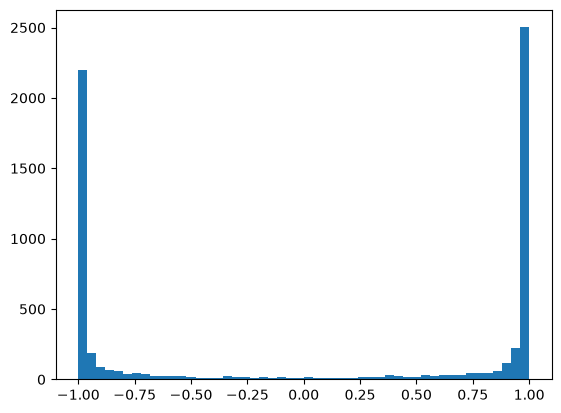

In [ ]:
plt.hist(h.view(-1).tolist(), 50)

(array([  4.,   0.,   0.,   2.,   5.,   5.,  12.,  18.,  19.,  31.,  42.,
         58.,  82.,  78., 112., 144., 192., 284., 346., 416., 440., 356.,
        294., 274., 325., 432., 456., 405., 310., 315., 223., 207., 124.,
        117., 107.,  54.,  24.,  22.,  24.,   9.,   9.,   4.,   5.,   4.,
          1.,   7.,   0.,   0.,   1.,   1.]),
 array([-17.91098404, -17.14182041, -16.37265678, -15.60349316,
        -14.83432953, -14.0651659 , -13.29600227, -12.52683865,
        -11.75767502, -10.98851139, -10.21934776,  -9.45018414,
         -8.68102051,  -7.91185688,  -7.14269325,  -6.37352962,
         -5.604366  ,  -4.83520237,  -4.06603874,  -3.29687511,
         -2.52771149,  -1.75854786,  -0.98938423,  -0.2202206 ,
          0.54894302,   1.31810665,   2.08727028,   2.85643391,
          3.62559753,   4.39476116,   5.16392479,   5.93308842,
          6.70225204,   7.47141567,   8.2405793 ,   9.00974293,
          9.77890656,  10.54807018,  11.31723381,  12.08639744,
         12.855561

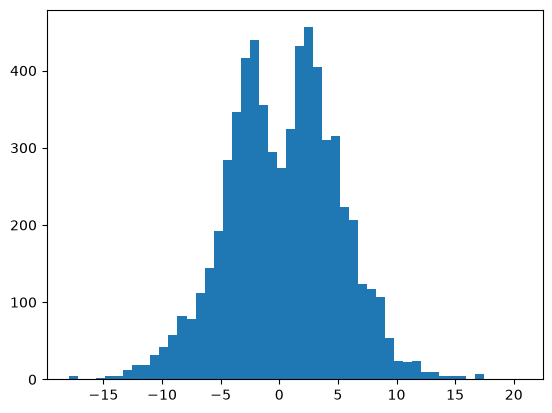

In [ ]:
plt.hist(hpreact.view(-1).tolist(), 50)

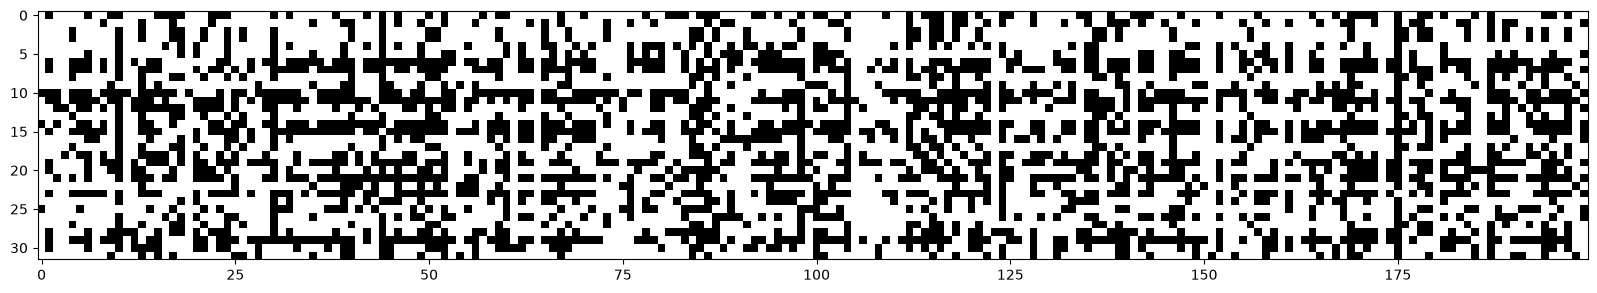

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')
#white if true, black if false
#a whole lot of white -> in the flat tail of tanh
#if entire column white called a dead neuron and will never nearn

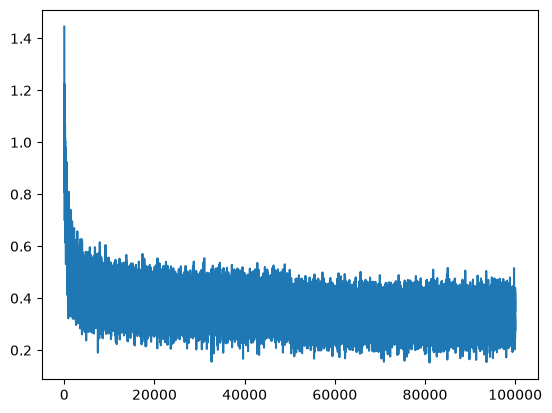

In [ ]:

plt.plot(lossi)
plt.show()

In [ ]:
#training split, dev/validation split, test split
# 80, 10, 10 %

In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
    x,y = {
        "train": (Xtr, Ytr),
        "dev": (Xdev, Ydev),
        "test": (Xte, Yte),
    }[split]

    emb = C[x]                                        # (N, block_size, n_embd)
    embcat = emb.view((emb.shape[0], -1))             # (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1                        # (N, n_hidden)
    h = torch.tanh(hpreact)                           # (N, n_hidden)
    logits = h @ W2 + b2                              # (N, vocab_size)
    loss = F.cross_entropy(logits, y)

    print(f"{split} loss: {loss.item()}")

split_loss("train")
split_loss("dev")

train loss: 2.1780362129211426
dev loss: 2.205266237258911


In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
        # forward pass the neural net
        emb = C[torch.tensor([context])]              # (1,block_size,n_embd)
        x = emb.view(emb.shape[0], -1)                # concatenate the vectors
        h = torch.tanh(x @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
            break

    print(''.join(itos[i] for i in out))              # decode and print the generated word

carlah.
ambrilli.
kimri.
rey.
cassandan.
jazonen.
den.
rha.
kaqui.
nellara.
chaiir.
kaleig.
dham.
jorn.
quint.
sulin.
alia.
bick.
jerrgiearynix.
kaeliigs.
